# Phân tích dữ liệu Bất động sản Gia Lai

Notebook này gồm 3 phần:

1. **Nạp & khảo sát dữ liệu thô**
2. **Làm sạch dữ liệu** (chuẩn hoá kiểu số, chuẩn hoá danh mục, loại outlier phi thực tế, gỡ trùng lặp)
3. **Phân tích khám phá (EDA)**: phân phối giá, so sánh theo loại hình/khu vực/pháp lý, tương quan, và các tin đăng nổi bật


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Bật hiển thị biểu đồ trong notebook
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Đường dẫn file dữ liệu gốc (đổi lại nếu cần)
RAW_PATH = 'bds_gialai_10nguon_da_sua_20260718.csv'
CLEAN_PATH = 'bds_gialai_10nguon_da_sua_20260718_clean.csv'
df_raw = pd.read_csv(RAW_PATH)
print('Kích thước dữ liệu thô:', df_raw.shape)
df_raw.head()

Kích thước dữ liệu thô: (800, 34)


,Loai_hinh,Tieu_de,Gia_niem_yet,Dien_tich_niem_yet,Link,Trang,Dia_chi_chi_tiet,Khu_vuc,Gia_m2,Khoảng giá,...,Hướng nhà,Hướng ban công,Pháp lý,Nội thất,Số tầng,Mặt tiền,Đường vào,Mức giá điện,Nguon,Vung_goc
0,Căn hộ chung cư,"CĂN HỘ BIỂN 65M² 2PN 2WC GIÁ FULL CHỈ 2,4 TỶ, ...","2,4 tỷ",65 m²,https://batdongsan.com.vn/ban-can-ho-chung-cu-...,1,"Simona Heights , Phường Lê Lợi, Thành phố Quy ...",Quy Nhơn,"~36,92 triệu/m²","2,4 tỷ",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Căn hộ chung cư,Bán CC đẹp xuất sắc tại Nhà ở xã Hội Solrise N...,884 triệu,58 m²,https://batdongsan.com.vn/ban-can-ho-chung-cu-...,1,"Nhà ở Xã Hội Solrise Nhơn Phú 2, Solrise Nhơn ...",Quy Nhơn,"~15,24 triệu/m²",884 triệu,...,Đông - Nam,Đông - Nam,Sổ đỏ/ Sổ hồng,Cơ bản,NaN,NaN,NaN,NaN,NaN,NaN
2,Căn hộ chung cư,GẤP! Simona Heights Quy Nhơn còn 3 căn giá tốt...,"2,4 tỷ",65 m²,https://batdongsan.com.vn/ban-can-ho-chung-cu-...,1,"Simona Heights , Phường Lê Lợi, Thành phố Quy ...",Quy Nhơn,"~36,92 triệu/m²","2,4 tỷ",...,Đông - Nam,Đông - Nam,Hợp đồng mua bán,Đầy đủ,NaN,NaN,NaN,NaN,NaN,NaN
3,Căn hộ chung cư,Chủ ngộp cắt lỗ bán gấp căn hộ Studio Quy Nhơn...,1 tỷ,47 m²,https://batdongsan.com.vn/ban-condotel-duong-n...,1,"TMS Luxury Hotel & Residences, Đường Nguyễn Hu...",Quy Nhơn,"~21,28 triệu/m²",1 tỷ,...,Đông - Nam,NaN,Đang chờ sổ,Đầy đủ,NaN,NaN,NaN,NaN,NaN,NaN
4,Căn hộ chung cư,Độc quyền căn góc 3PN trực diện biển Quy Nhơn ...,"3,83 tỷ","94,11 m²",https://batdongsan.com.vn/ban-can-ho-chung-cu-...,1,"Simona Heights , Đường Trần Hưng Đạo, Phường L...",Quy Nhơn,"~40,74 triệu/m²","3,83 tỷ",...,NaN,NaN,Sổ đỏ/ Sổ hồng,Đầy đủ,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Khảo sát dữ liệu thô

In [16]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Loai_hinh              800 non-null    object
 1   Tieu_de                800 non-null    object
 2   Gia_niem_yet           800 non-null    object
 3   Dien_tich_niem_yet     800 non-null    object
 4   Link                   800 non-null    object
 5   Trang                  800 non-null    int64 
 6   Dia_chi_chi_tiet       775 non-null    object
 7   Khu_vuc                796 non-null    object
 8   Gia_m2                 543 non-null    object
 9   Khoảng giá             584 non-null    object
 10  Diện tích              604 non-null    object
 11  Mo_ta                  798 non-null    object
 12  Ten_du_an              416 non-null    object
 13  Trang_thai_du_an       409 non-null    object
 14  Dien_tich_du_an        116 non-null    object
 15  So_luong_can           

In [17]:
# Tỉ lệ thiếu dữ liệu theo cột (sắp xếp giảm dần)
(df_raw.isnull().mean() * 100).round(1).sort_values(ascending=False).to_frame('% thiếu')

,% thiếu
Mức giá điện,95.0
Số tầng,87.4
Dien_tich_du_an,85.5
So_toa,84.1
So_luong_can,80.4
Đường vào,75.9
Mặt tiền,74.8
Hướng ban công,73.1
Nguon,73.0
Vung_goc,73.0


**Nhận xét nhanh:**
- Nhiều cột đặc thù dự án (`Mức giá điện`, `Số tầng`, `Diện tích dự án`, `Số toà`...) thiếu trên 80% vì phần lớn tin đăng là nhà/đất lẻ, không thuộc dự án.
- `Gia_VND` và `Gia_per_m2_VND` là các cột số đã được chuẩn hoá sẵn từ nguồn, nhưng vẫn đang ở kiểu chuỗi (`object`) nên cần ép kiểu.
- Một số cột dạng số bị lẫn đơn vị trong text: `Số phòng ngủ` ("2 phòng"), `Số tầng` ("4 tầng"), `Mặt tiền` ("5,5 m")... cần tách số ra.

## 2. Làm sạch dữ liệu

### 2.1. Đổi tên cột về dạng snake_case (không dấu cách)

Cột có dấu cách/tiếng Việt có dấu trong tên rất dễ gây lỗi khi gõ code (`df['Số tầng']` vs `df.So_tang`). Đổi tên một lần để toàn bộ notebook thao tác nhất quán.

In [18]:
rename_map = {
    'Số phòng ngủ': 'So_phong_ngu',
    'Số phòng tắm, vệ sinh': 'So_phong_tam',
    'Hướng nhà': 'Huong_nha',
    'Hướng ban công': 'Huong_ban_cong',
    'Pháp lý': 'Phap_ly',
    'Nội thất': 'Noi_that',
    'Số tầng': 'So_tang',
    'Mặt tiền': 'Mat_tien',
    'Đường vào': 'Duong_vao',
    'Mức giá điện': 'Muc_gia_dien',
    'Khoảng giá': 'Khoang_gia',
    'Diện tích': 'Dien_tich_raw',
}

df = df_raw.rename(columns=rename_map).copy()
df.columns.tolist()

['Loai_hinh',
 'Tieu_de',
 'Gia_niem_yet',
 'Dien_tich_niem_yet',
 'Link',
 'Trang',
 'Dia_chi_chi_tiet',
 'Khu_vuc',
 'Gia_m2',
 'Khoang_gia',
 'Dien_tich_raw',
 'Mo_ta',
 'Ten_du_an',
 'Trang_thai_du_an',
 'Dien_tich_du_an',
 'So_luong_can',
 'So_toa',
 'Chu_dau_tu',
 'Thuoc_du_an',
 'Gia_VND',
 'Dien_tich_m2',
 'Gia_per_m2_VND',
 'So_phong_ngu',
 'So_phong_tam',
 'Huong_nha',
 'Huong_ban_cong',
 'Phap_ly',
 'Noi_that',
 'So_tang',
 'Mat_tien',
 'Duong_vao',
 'Muc_gia_dien',
 'Nguon',
 'Vung_goc']

### 2.2. Chuẩn hoá các cột số

- `Gia_VND`, `Dien_tich_m2`, `Gia_per_m2_VND`: đã là chuỗi số thuần, chỉ cần `pd.to_numeric`.
- `So_phong_ngu`, `So_phong_tam`, `So_tang`, `Mat_tien`, `Duong_vao`: lẫn đơn vị text (vd `"2 phòng"`, `"5,5 m"`) → dùng regex tách phần số, đổi dấu phẩy thập phân Việt Nam (`,`) thành dấu chấm (`.`).

In [19]:
print(type(df.loc[0, "Gia_VND"]))
print(type(df.loc[0, "Dien_tich_m2"]))

<class 'str'>
<class 'str'>


In [20]:
print(repr(df.loc[0, "Gia_VND"]))
print(repr(df.loc[0, "Dien_tich_m2"]))


'2400000000'
'65'


Vì trong Gia_VND có 7 giá trị " thỏa thuận" nên dùng chuyển thành giá trị NaN

In [21]:
import pandas as pd

df["Gia_VND"] = pd.to_numeric(df["Gia_VND"], errors="coerce")
df["Dien_tich_m2"] = pd.to_numeric(df["Dien_tich_m2"], errors="coerce")

In [22]:

df["Gia_m2"] = df["Gia_VND"] / df["Dien_tich_m2"]

In [23]:
def extract_number(series):
    """Tách phần số từ chuỗi dạng '2 phòng', '5,5 m', '4 tầng'..."""
    cleaned = (
        series.astype(str)
        .str.replace(r'[^0-9,\.]', '', regex=True)   # chỉ giữ số, dấu , và .
        .str.replace(',', '.', regex=False)            # 5,5 -> 5.5
    )
    return pd.to_numeric(cleaned, errors='coerce')

# Các cột đã là số thuần
for col in ['Gia_VND', 'Dien_tich_m2', 'Gia_per_m2_VND']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Các cột lẫn đơn vị text
for col in ['So_phong_ngu', 'So_phong_tam', 'So_tang', 'Mat_tien', 'Duong_vao']:
    df[col] = extract_number(df[col])

df[['Gia_VND', 'Dien_tich_m2', 'Gia_per_m2_VND', 'So_phong_ngu', 'So_phong_tam', 'So_tang']].describe().round(2)

,Gia_VND,Dien_tich_m2,Gia_per_m2_VND,So_phong_ngu,So_phong_tam,So_tang
count,7.160000e+02,748.00,7.140000e+02,364.00,358.00,101.00
mean,5.506248e+09,260.63,1.270941e+08,2.64,2.40,2.72
std,3.371820e+10,1861.41,1.868625e+09,2.72,2.72,1.19
min,1.500000e+04,0.00,1.200000e+02,1.00,1.00,1.00
25%,1.300000e+09,65.00,1.000000e+07,2.00,1.00,2.00
50%,2.100000e+09,86.30,2.678571e+07,2.00,2.00,3.00
75%,3.512500e+09,160.00,4.051819e+07,3.00,2.00,4.00
max,8.490000e+11,50000.00,4.800000e+10,40.00,40.00,5.00


### 2.3. Chuẩn hoá các cột danh mục (categorical)

Dữ liệu crawl từ 10 nguồn khác nhau nên cùng một giá trị bị viết nhiều kiểu, ví dụ:
- `"Plei Ku"` và `"Pleiku"` cùng là một khu vực
- `"Sổ đỏ"`, `"Sổ hồng"`, `"Sổ đỏ/ Sổ hồng"`, `"Sổ đỏ/ Sổ hồng."` (dư dấu chấm) cùng một loại pháp lý
- `"Bán đất nền"` và `"Đất nền"` cùng một loại hình

Bước dưới đây strip khoảng trắng, bỏ dấu chấm cuối câu, rồi gộp các biến thể trùng nghĩa lại với nhau.

In [24]:
def clean_text(series):
    s = series.astype(str).str.strip()
    s = s.replace({'nan': np.nan, 'None': np.nan, '': np.nan})
    s = s.str.rstrip('.').str.strip()
    return s

cat_cols = ['Loai_hinh', 'Khu_vuc', 'Phap_ly', 'Huong_nha', 'Huong_ban_cong', 'Noi_that']
for col in cat_cols:
    df[col] = clean_text(df[col])

# Gộp các biến thể trùng nghĩa (bổ sung thêm khi phát hiện biến thể mới)
df['Loai_hinh'] = df['Loai_hinh'].replace({
    'Bán đất nền': 'Đất nền',
    'Bán nhà riêng': 'Nhà riêng',
    'Bán nhà mặt phố': 'Nhà mặt phố',
})
df['Khu_vuc'] = df['Khu_vuc'].replace({'Plei Ku': 'Pleiku'})
df['Phap_ly'] = df['Phap_ly'].replace({
    'Sổ đỏ': 'Sổ đỏ/ Sổ hồng',
    'Sổ hồng': 'Sổ đỏ/ Sổ hồng',
})

for col in cat_cols:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False).head(10), '\n')

--- Loai_hinh ---
Loai_hinh
Căn hộ chung cư          536
Đất nền                  186
Nhà mặt phố               39
Nhà riêng                 23
Nhà biệt thự, liền kề     13
Khác                       3
Name: count, dtype: int64 

--- Khu_vuc ---
Khu_vuc
Quy Nhơn     443
Pleiku       228
Vân Canh      27
Phù Cát       25
Phù Mỹ        12
Ia Grai       10
An Nhơn        9
Hoài Nhơn      7
Tuy Phước      7
Chư Sê         7
Name: count, dtype: int64 

--- Phap_ly ---
Phap_ly
Sổ đỏ/ Sổ hồng      446
NaN                 285
Hợp đồng mua bán     56
Đang chờ sổ          12
Xây dựng Cấp Sổ       1
Name: count, dtype: int64 

--- Huong_nha ---
Huong_nha
NaN           476
Đông - Nam    112
Đông - Bắc     64
Tây - Bắc      43
Tây - Nam      38
Đông           28
Nam            15
Tây            12
Bắc            12
Name: count, dtype: int64 

--- Huong_ban_cong ---
Huong_ban_cong
NaN           585
Đông - Nam     66
Tây - Bắc      45
Tây - Nam      39
Đông - Bắc     28
Đông           22
Nam         

### 2.4. Loại bỏ giá trị phi thực tế, gỡ trùng lặp, tính lại giá/m²

Giá trị min/max thô cho thấy có tin lỗi rõ rệt (giá 15.000đ, diện tích 50.000m²...). Áp dụng ngưỡng hợp lý theo nghiệp vụ thay vì chỉ dùng IQR thuần tuý (IQR sẽ cắt bỏ quá nhiều tin đất nền hợp lệ vì giá/diện tích đất vốn dao động rất lớn).

Ngưỡng áp dụng:
- Giá: 50 triệu – 100 tỷ VND
- Diện tích: 10 – 5.000 m²

Sau đó gỡ trùng theo `Link` tin đăng và tính lại `Gia_per_m2_VND` cho các dòng có đủ Giá + Diện tích nhưng thiếu giá/m².

In [25]:
n_before = len(df)

df_clean = df[df['Gia_VND'].isna() | df['Gia_VND'].between(50_000_000, 100_000_000_000)].copy()
df_clean = df_clean[df_clean['Dien_tich_m2'].isna() | df_clean['Dien_tich_m2'].between(10, 5000)].copy()
print(f'Loại bỏ {n_before - len(df_clean)} dòng có giá/diện tích phi thực tế ({n_before} -> {len(df_clean)})')

n_before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['Link'])
print(f'Loại bỏ {n_before_dedup - len(df_clean)} dòng trùng link tin đăng')

# Tính lại giá/m² khi thiếu nhưng có đủ giá và diện tích
mask = (df_clean['Gia_per_m2_VND'].isna()& df_clean['Gia_VND'].notna()& df_clean['Dien_tich_m2'].notna()& (df_clean['Dien_tich_m2'] > 0))
df_clean.loc[mask, 'Gia_per_m2_VND'] = df_clean.loc[mask, 'Gia_VND'] / df_clean.loc[mask, 'Dien_tich_m2']
print(f'Tính bổ sung Gia_per_m2_VND cho {mask.sum()} dòng')

print('\nKích thước dữ liệu sau khi làm sạch:', df_clean.shape)
df_clean[['Gia_VND', 'Dien_tich_m2', 'Gia_per_m2_VND']].describe().round(2)

Loại bỏ 33 dòng có giá/diện tích phi thực tế (800 -> 767)
Loại bỏ 3 dòng trùng link tin đăng
Tính bổ sung Gia_per_m2_VND cho 0 dòng

Kích thước dữ liệu sau khi làm sạch: (764, 34)


,Gia_VND,Dien_tich_m2,Gia_per_m2_VND
count,6.800000e+02,713.00,6.800000e+02
mean,3.731301e+09,189.61,3.389229e+07
std,5.791787e+09,335.24,5.201133e+07
min,5.460000e+07,10.00,3.500000e+04
25%,1.307500e+09,65.00,1.200000e+07
50%,2.200000e+09,88.00,2.720588e+07
75%,3.600000e+09,160.00,4.026596e+07
max,7.700000e+10,3650.00,8.200000e+08


In [26]:
# Lưu dữ liệu đã làm sạch để dùng lại cho các phân tích/notebook khác
df_clean.to_csv(CLEAN_PATH, index=False, encoding='utf-8-sig')
print(f'Đã lưu {len(df_clean)} dòng vào {CLEAN_PATH}')

Đã lưu 764 dòng vào bds_gialai_10nguon_da_sua_20260718_clean.csv


## 3. Phân tích khám phá dữ liệu (EDA)

Từ đây trở đi, toàn bộ phân tích dùng `df_clean`.

### 3.1. Phân phối giá bất động sản

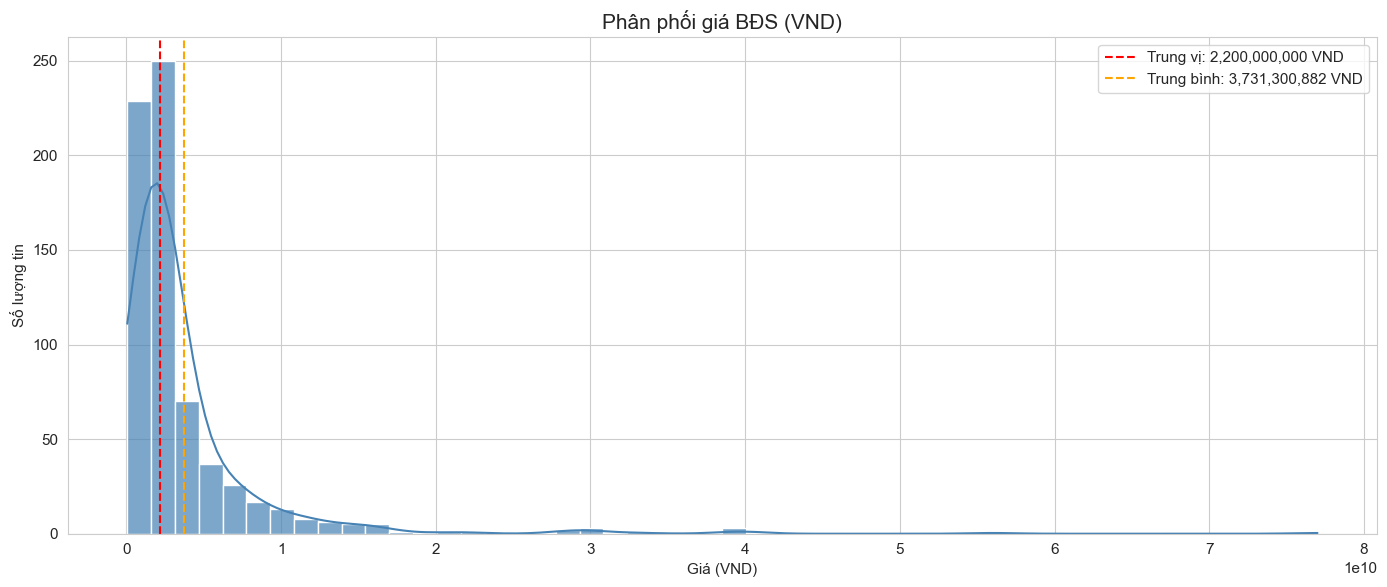

In [27]:
plt.figure(figsize=(14, 6))
gia = df_clean['Gia_VND'].dropna()
sns.histplot(gia, bins=50, kde=True, color='steelblue', alpha=0.7)
plt.axvline(gia.median(), color='red', linestyle='--', label=f'Trung vị: {gia.median():,.0f} VND')
plt.axvline(gia.mean(), color='orange', linestyle='--', label=f'Trung bình: {gia.mean():,.0f} VND')
plt.title('Phân phối giá BĐS (VND)', fontsize=15)
plt.xlabel('Giá (VND)')
plt.ylabel('Số lượng tin')
plt.legend()
plt.tight_layout()
plt.show()

### 3.2. Giá theo loại hình bất động sản

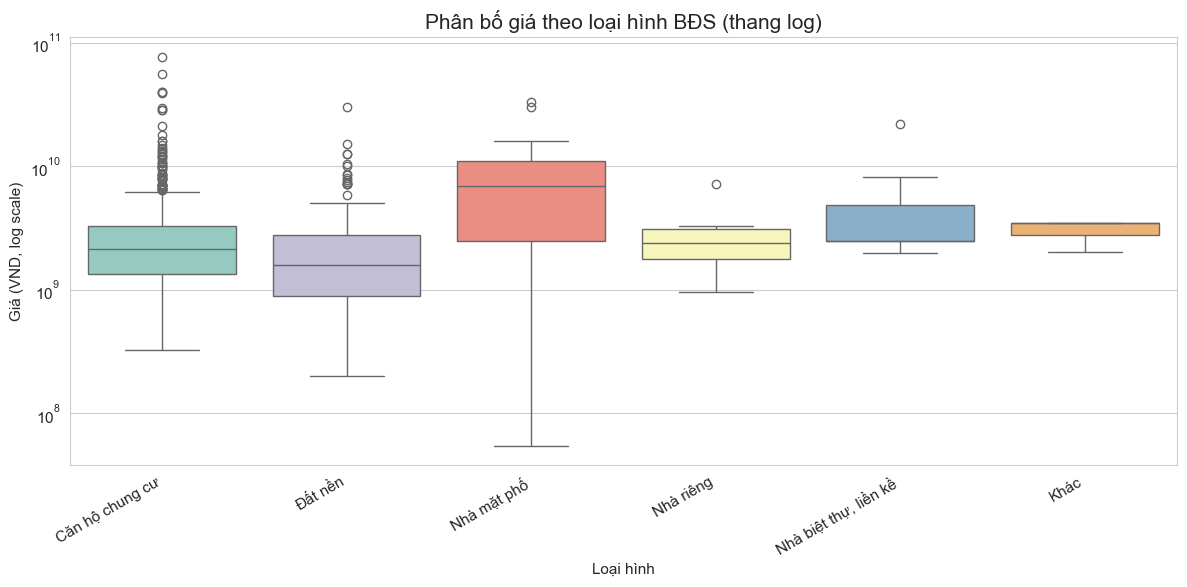

In [28]:
order = df_clean['Loai_hinh'].value_counts().index
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, x='Loai_hinh', y='Gia_VND', order=order, hue='Loai_hinh', palette='Set3', legend=False)
plt.yscale('log')
plt.title('Phân bố giá theo loại hình BĐS (thang log)', fontsize=15)
plt.xlabel('Loại hình')
plt.ylabel('Giá (VND, log scale)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 3.3. Ma trận tương quan giữa các biến số

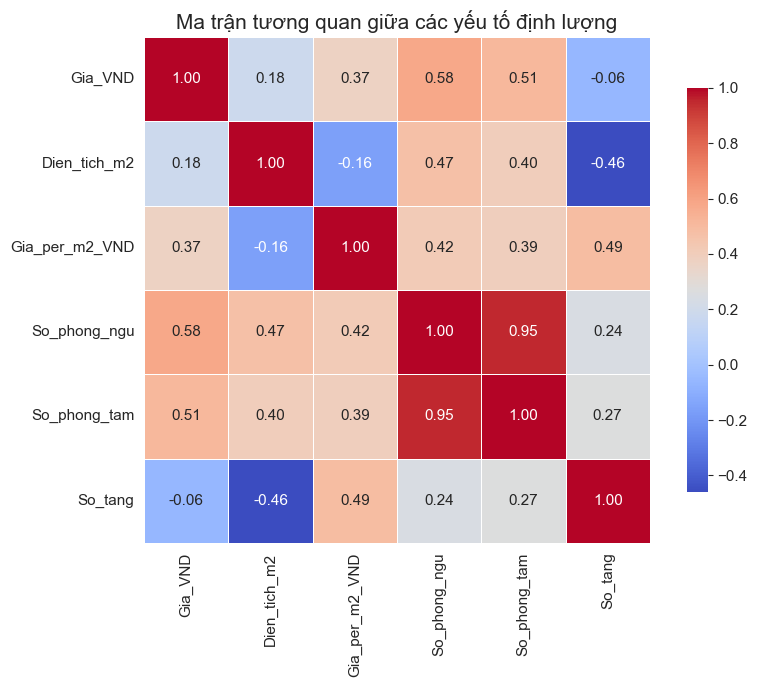

In [29]:
corr_cols = ['Gia_VND', 'Dien_tich_m2', 'Gia_per_m2_VND', 'So_phong_ngu', 'So_phong_tam', 'So_tang']
corr_cols = [c for c in corr_cols if c in df_clean.columns]
corr_df = df_clean[corr_cols]

plt.figure(figsize=(9, 7))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Ma trận tương quan giữa các yếu tố định lượng', fontsize=15)
plt.tight_layout()
plt.show()

### 3.4. Quan hệ giữa diện tích và giá

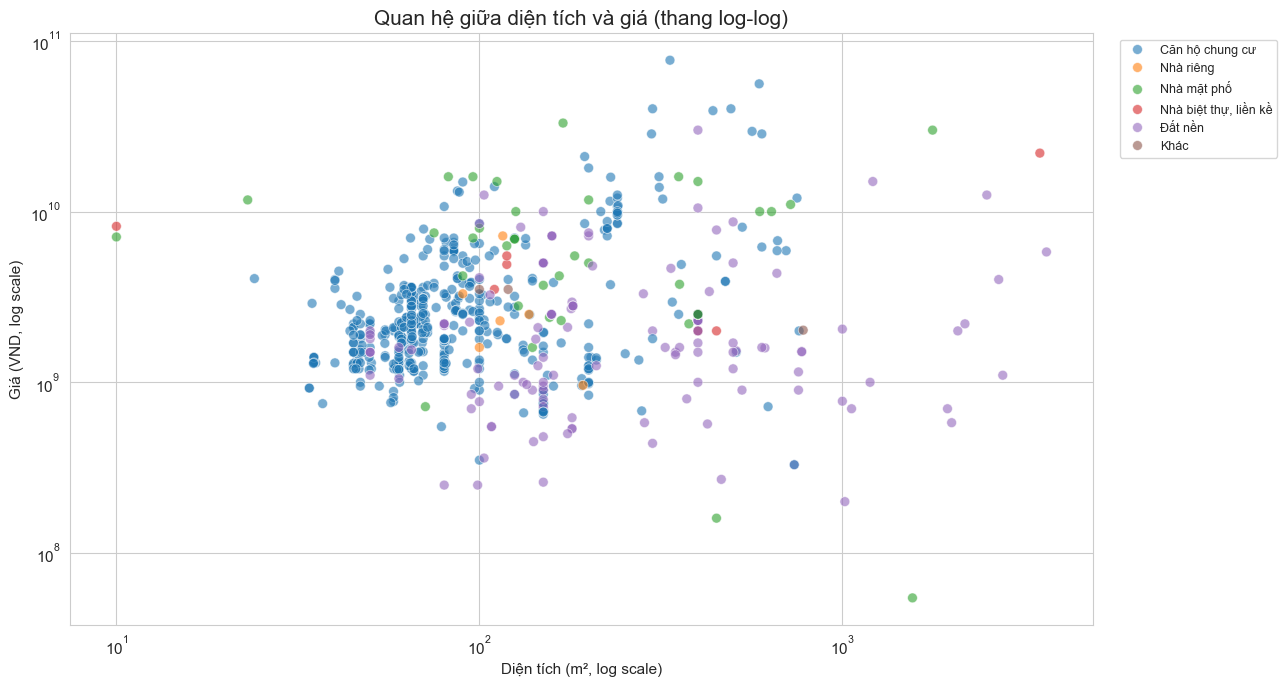

In [30]:
sub = df_clean.dropna(subset=['Dien_tich_m2', 'Gia_VND'])

plt.figure(figsize=(13, 7))
sns.scatterplot(data=sub, x='Dien_tich_m2', y='Gia_VND', hue='Loai_hinh', alpha=0.6, s=50)
plt.xscale('log')
plt.yscale('log')
plt.title('Quan hệ giữa diện tích và giá (thang log-log)', fontsize=15)
plt.xlabel('Diện tích (m², log scale)')
plt.ylabel('Giá (VND, log scale)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

### 3.5. Giá trung bình theo khu vực (m²)

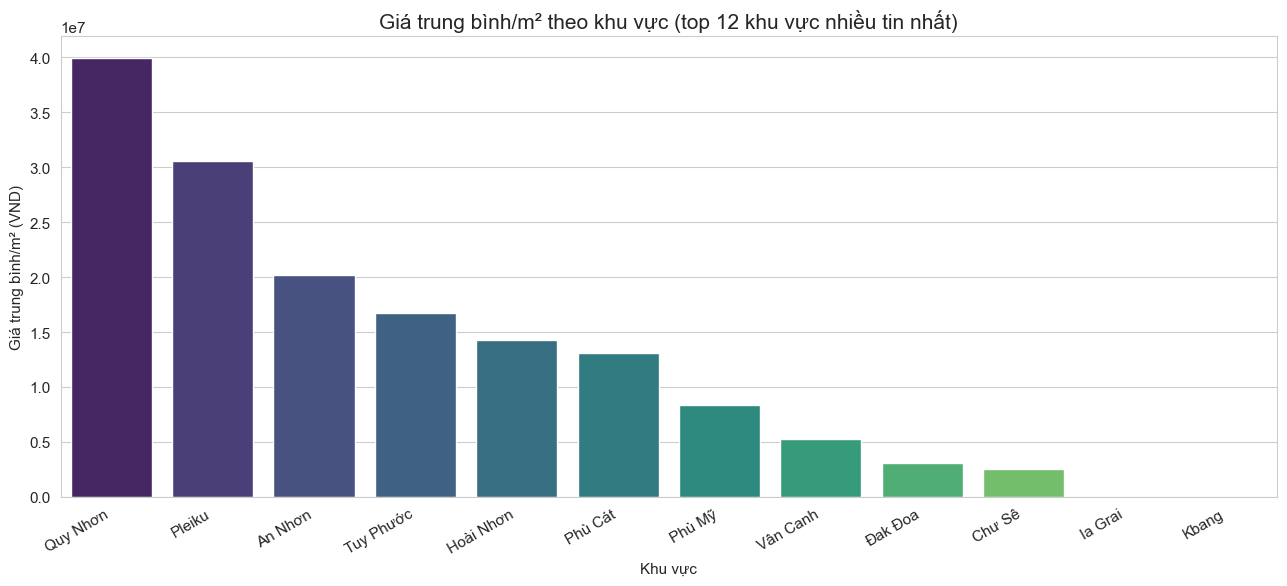

In [31]:
top_n = 12
top_khu_vuc = df_clean['Khu_vuc'].value_counts().head(top_n).index
kv_mean = (
    df_clean[df_clean['Khu_vuc'].isin(top_khu_vuc)]
    .groupby('Khu_vuc')['Gia_per_m2_VND']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(13, 6))
sns.barplot(x=kv_mean.index, y=kv_mean.values, hue=kv_mean.index, palette='viridis', legend=False)
plt.title(f'Giá trung bình/m² theo khu vực (top {top_n} khu vực nhiều tin nhất)', fontsize=15)
plt.xlabel('Khu vực')
plt.ylabel('Giá trung bình/m² (VND)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 3.6. Giá theo pháp lý và hướng nhà

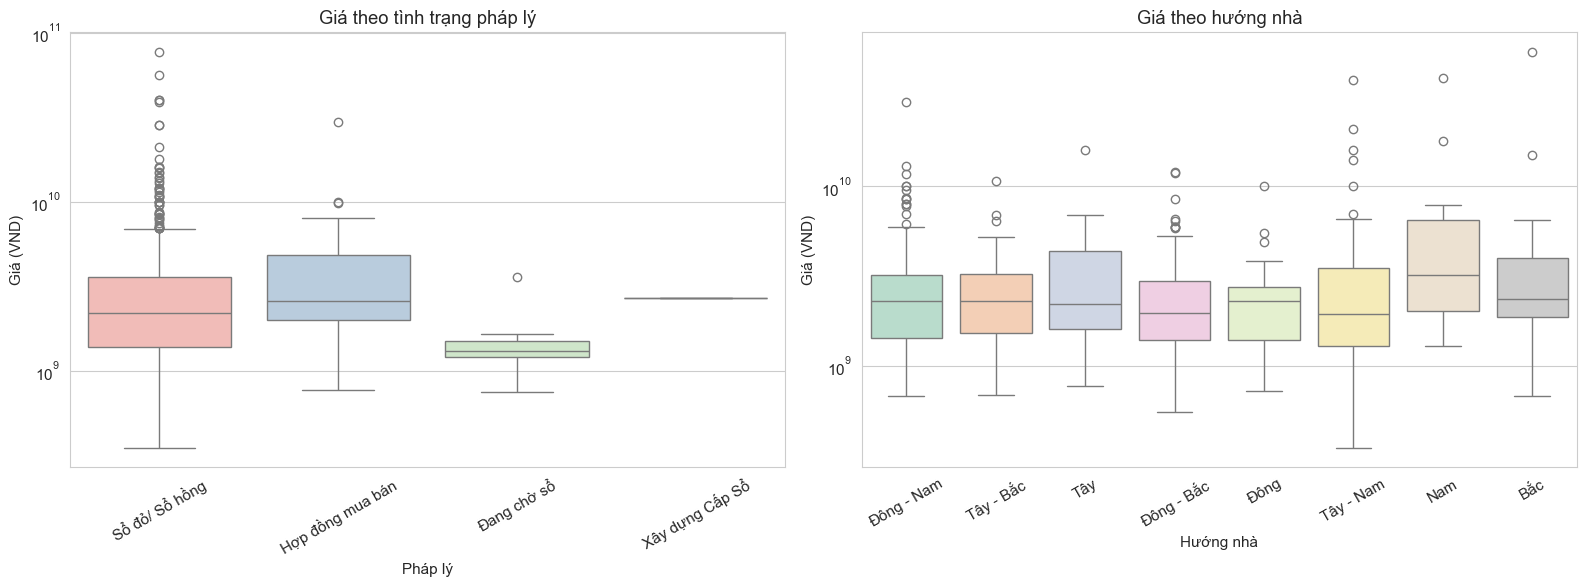

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(ax=axes[0], data=df_clean, x='Phap_ly', y='Gia_VND', hue='Phap_ly', palette='Pastel1', legend=False)
axes[0].set_title('Giá theo tình trạng pháp lý')
axes[0].set_xlabel('Pháp lý')
axes[0].set_ylabel('Giá (VND)')
axes[0].set_yscale('log')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(ax=axes[1], data=df_clean, x='Huong_nha', y='Gia_VND', hue='Huong_nha', palette='Pastel2', legend=False)
axes[1].set_title('Giá theo hướng nhà')
axes[1].set_xlabel('Hướng nhà')
axes[1].set_ylabel('Giá (VND)')
axes[1].set_yscale('log')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 3.7. Top tin đăng có giá/m² cao nhất và thấp nhất

In [33]:
cols_show = ['Tieu_de', 'Khu_vuc', 'Loai_hinh', 'Gia_VND', 'Dien_tich_m2', 'Gia_per_m2_VND', 'Link']
priced = df_clean.dropna(subset=['Gia_per_m2_VND'])

print('--- Top 10 giá/m² cao nhất ---')
display(priced.nlargest(10, 'Gia_per_m2_VND')[cols_show])

print('\n--- Top 10 giá/m² thấp nhất ---')
display(priced.nsmallest(10, 'Gia_per_m2_VND')[cols_show])

--- Top 10 giá/m² cao nhất ---


,Tieu_de,Khu_vuc,Loai_hinh,Gia_VND,Dien_tich_m2,Gia_per_m2_VND,Link
756,CẦN BÁN NHÀ VƯỜN TRUNG TÂM PLEIKU - GIA LAI,Pleiku,"Nhà biệt thự, liền kề",8.200000e+09,10.00,820000000.0,https://alonhadat.com.vn/can-ban-nha-vuon-trun...
602,Bán nhà 12 Cù Chính Lan Tp.Pleiku,Pleiku,Nhà mặt phố,7.100000e+09,10.00,710000000.0,https://alonhadat.com.vn/ban-nha-hoac-cho-thue...
612,Bán nhà mặt tiền đẹp - Vị trí vàng - Kinh doan...,Pleiku,Nhà mặt phố,1.170000e+10,23.00,508695652.0,https://alonhadat.com.vn/ban-nha-mat-tien-116-...
293,BÁN NHANH ĐẤT VIP MẶT TIỀN ĐƯỜNG XUÂN DIỆU VIE...,Quy Nhơn,Căn hộ chung cư,7.700000e+10,335.00,229850746.0,https://batdongsan.com.vn/ban-dat-duong-xuan-d...
580,Siêu vị trí. Trung tâm Pleiku - kế sân vận độn...,Pleiku,Nhà mặt phố,1.600000e+10,82.13,194813101.0,https://batdongsan.com.vn/ban-nha-mat-pho-duon...
729,chính chủ bán căn nhà 4 mê mặt tiền Quang Trun...,Pleiku,Nhà mặt phố,3.300000e+10,170.00,194117647.0,https://homedy.com/ban-nha-mat-pho-thanh-pho-p...
120,TC 4 tỷ tìm nhà mặt tiền kinh doanh biển thì k...,Quy Nhơn,Căn hộ chung cư,4.050000e+09,24.00,168750000.0,https://batdongsan.com.vn/ban-nha-mat-pho-phuo...
736,"Bán nhà 5,9x17,5 mặt tiền Phan Đình Phùng,PLei...",Pleiku,Nhà mặt phố,1.600000e+10,96.00,166666667.0,https://homedy.com/ban-nha-mat-pho-thanh-pho-p...
441,Siêu phẩm nhà đẹp 5 tầng 2 mặt tiền phố Bình H...,Quy Nhơn,Căn hộ chung cư,1.490000e+10,90.00,165555556.0,https://batdongsan.com.vn/ban-nha-mat-pho-duon...
301,"Bán nhà vị trí trung tâm, có dòng tiền cho thu...",Quy Nhơn,Căn hộ chung cư,1.320000e+10,87.00,151724138.0,https://batdongsan.com.vn/ban-nha-mat-pho-duon...



--- Top 10 giá/m² thấp nhất ---


,Tieu_de,Khu_vuc,Loai_hinh,Gia_VND,Dien_tich_m2,Gia_per_m2_VND,Link
743,CẦN CHO THUÊ KHO KCN DIÊN PHÚ - GIA LAI - 1560M2,Pleiku,Nhà mặt phố,5.460000e+07,1560.0,35000.0,https://muaban.net/bat-dong-san/cho-thue-nha-x...
644,200tr có 1 sào đất đẹp Gia Lai huyện Chư Pãh (...,Pleiku,Đất nền,2.000000e+08,1015.9,196870.0,https://homedy.com/ban-dat-huyen-chu-pah-gia-l...
620,6 ngày trước,Pleiku,Đất nền,5.800000e+08,2000.0,290000.0,https://www.nhatot.com/mua-ban-huyen-chu-se-gi...
744,CHO THUÊ MẶT BẰNG VỊ TRÍ ĐẸP – TRUNG TÂM TP. P...,Pleiku,Nhà mặt phố,1.600000e+08,450.0,355556.0,https://muaban.net/bat-dong-san/cho-thue-mat-b...
624,Tin hết hạn,Pleiku,Đất nền,7.000000e+08,1948.0,359343.0,https://www.nhatot.com/mua-ban-huyen-ia-grai-g...
619,Gia Lai - Bán đất vườn có thổ cư 2766 m2 của g...,Đak Đoa,Đất nền,1.100000e+09,2766.0,397686.0,https://www.nhatot.com/mua-ban-dat-huyen-dak-d...
623,2 tháng trước,Pleiku,Đất nền,3.290000e+08,737.0,446404.0,https://www.nhatot.com/mua-ban-huyen-ia-grai-g...
760,Tin hết hạn,Pleiku,Căn hộ chung cư,3.290000e+08,737.0,446404.0,https://nhadat24h.net/ban-nha-dat-huyen-ia-gra...
645,Cấn bán lô đất 464m2 giá chỉ 270tr có 100m2 th...,Pleiku,Đất nền,2.700000e+08,464.0,581897.0,https://homedy.com/ban-dat-huyen-ia-pa-gia-lai...
708,Chính Chủ Cần Bán DT 1060m View Thung Lũng Điệ...,Pleiku,Đất nền,7.000000e+08,1060.0,660377.0,https://homedy.com/ban-dat-thanh-pho-pleiku-gi...


### 3.8. Số lượng tin theo nguồn dữ liệu

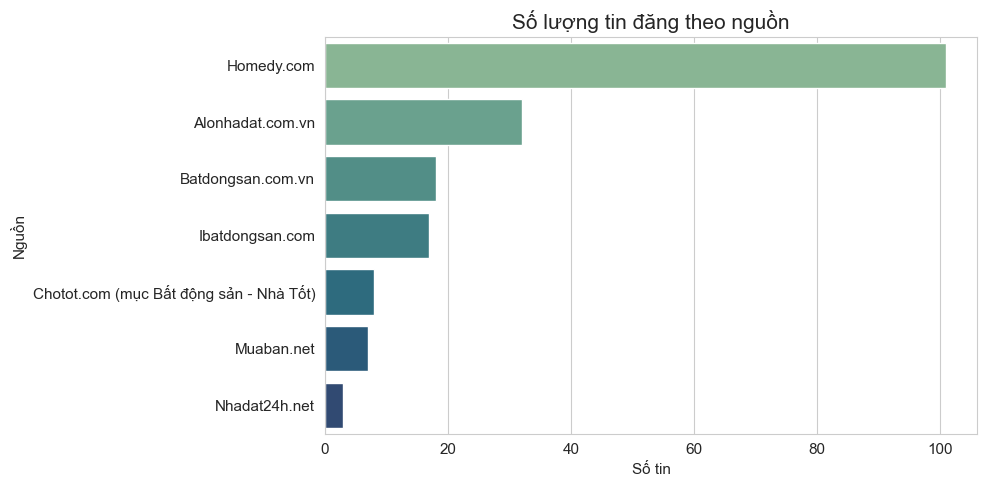

In [34]:
nguon_counts = df_clean['Nguon'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=nguon_counts.values, y=nguon_counts.index, hue=nguon_counts.index, palette='crest', legend=False)
plt.title('Số lượng tin đăng theo nguồn', fontsize=15)
plt.xlabel('Số tin')
plt.ylabel('Nguồn')
plt.tight_layout()
plt.show()

### 3.9. WordCloud mô tả tin đăng

Cell này cần package `wordcloud` (`pip install wordcloud`). Nếu chưa cài, cell sẽ báo hướng dẫn thay vì lỗi crash.

In [35]:
pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\DN\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


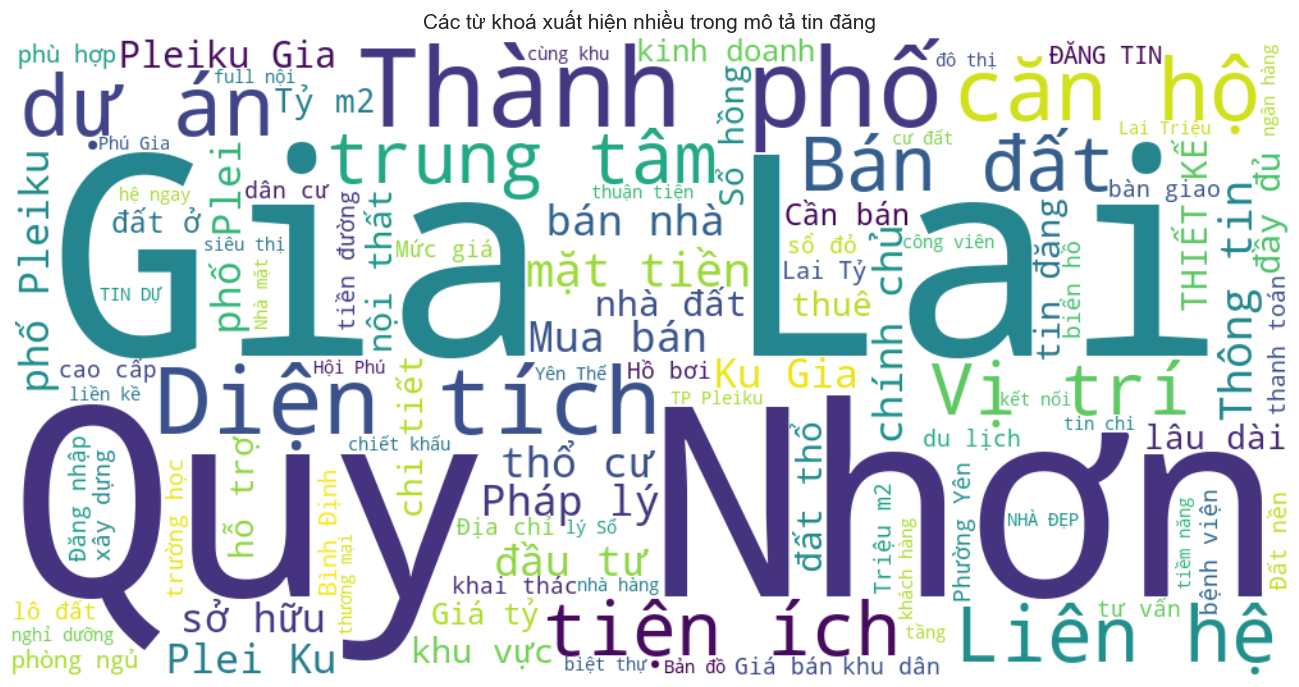

In [36]:
try:
    from wordcloud import WordCloud

    stopwords_vn = {
        'của', 'và', 'với', 'cho', 'có', 'được', 'sẽ', 'là', 'một', 'các',
        'này', 'tại', 'trong', 'từ', 'đã', 'khi', 'để', 'không', 'rất', 'ra',
    }
    text = ' '.join(df_clean['Mo_ta'].dropna().astype(str))
    wc = WordCloud(width=1000, height=500, background_color='white',
                    colormap='viridis', max_words=100, stopwords=stopwords_vn).generate(text)

    plt.figure(figsize=(14, 7))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title('Các từ khoá xuất hiện nhiều trong mô tả tin đăng', fontsize=15)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Chưa cài package 'wordcloud'. Chạy: pip install wordcloud")

## 4. Tổng kết

- Kết quả sau làm sạch
  - Từ 800 tin → 764 tin hợp lệ (loại bỏ 33 outlier + 3 trùng lặp)
  - Trung vị: ~2.1 tỷ VND

  - Trung bình: ~3.73 tỷ VND (bị kéo lên bởi các giao dịch cao cấp)

  - Phân phối lệch phải điển hình của thị trường BĐS
- Giá theo khu vực:
  - Quy Nhơn	Cao nhất
  - Pleiku	Trung bình
  - Vân Canh, Phù Cát, Phù Mỹ	Thấp dần
  - => Quy Nhơn là khu vực "nóng" với mức giá cao gấp 2-3 lần các huyện lân cận
- Pháp lý và hướng nhà
  - Sổ đỏ/Sổ hồng: 446 tin → dòng sản pháp lý rõ ràng có giá cao hơn

  - Hợp đồng mua bán và Đang chờ sổ: giá thấp hơn đáng kể → rủi ro pháp lý được định giá

  - Hướng Đông - Nam: được ưa chuộng nhất (112 tin) với giá cao hơn mặt bằng chung
- Top 10 giá/m² cao nhất: Tập trung ở Pleiku và Quy Nhơn, chủ yếu là nhà mặt phố và biệt thự với diện tích nhỏ (10-90m²) nhưng giá trị cao

- Top 10 giá/m² thấp nhất: Chủ yếu là đất nền tại các huyện vùng ven, diện tích lớn (700-2.700m²)
